In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data selection
- use the 3 csv files
- covid,statewise_testing,covid_vaccine

# Data Loading

In [57]:
covid=pd.read_csv(r"C:\Users\pc\Downloads\EDA PROJECT\covid_19_india.csv")

# Data Observation

In [60]:
covid.head(1)

,sno,date,time,state/unionterritory,confirmedindiannational,confirmedforeignnational,cured,deaths,confirmed
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1


In [59]:
covid.columns=covid.columns.str.lower()
covid.columns

Index(['sno', 'date', 'time', 'state/unionterritory',
       'confirmedindiannational', 'confirmedforeignnational', 'cured',
       'deaths', 'confirmed'],
      dtype='object')

In [61]:
covid.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   sno                       18110 non-null  int64 
 1   date                      18110 non-null  object
 2   time                      18110 non-null  object
 3   state/unionterritory      18110 non-null  object
 4   confirmedindiannational   18110 non-null  object
 5   confirmedforeignnational  18110 non-null  object
 6   cured                     18110 non-null  int64 
 7   deaths                    18110 non-null  int64 
 8   confirmed                 18110 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.2+ MB


In [62]:
covid.isna().mean() * 100

sno                         0.0
date                        0.0
time                        0.0
state/unionterritory        0.0
confirmedindiannational     0.0
confirmedforeignnational    0.0
cured                       0.0
deaths                      0.0
confirmed                   0.0
dtype: float64

# Data type conversion

In [63]:
covid["date"]=pd.to_datetime(covid["date"],errors="coerce")

In [64]:
covid["year"] = covid["date"].dt.year

In [65]:
covid["month"] = covid["date"].dt.month

In [66]:
covid["confirmedindiannational"] = pd.to_numeric(
    covid["confirmedindiannational"], errors="coerce"
)

In [67]:
covid["confirmedforeignnational"] = pd.to_numeric(
    covid["confirmedforeignnational"], errors="coerce"
)

# missing values

In [68]:
covid.isna().sum()

sno                             0
date                            0
time                            0
state/unionterritory            0
confirmedindiannational     17664
confirmedforeignnational    17664
cured                           0
deaths                          0
confirmed                       0
year                            0
month                           0
dtype: int64

In [69]:
(covid.isnull().sum() / len(covid) * 100).round(2)

sno                          0.00
date                         0.00
time                         0.00
state/unionterritory         0.00
confirmedindiannational     97.54
confirmedforeignnational    97.54
cured                        0.00
deaths                       0.00
confirmed                    0.00
year                         0.00
month                        0.00
dtype: float64

In [70]:
covid = covid.drop(columns=[
    "confirmedindiannational",
    "confirmedforeignnational"])

In [71]:
covid.columns

Index(['sno', 'date', 'time', 'state/unionterritory', 'cured', 'deaths',
       'confirmed', 'year', 'month'],
      dtype='object')

### covid.describe()

In [72]:
covid.describe(include='object')

,time,state/unionterritory
count,18110,18110
unique,7,46
top,8:00 AM,Kerala
freq,16472,560


# Duplicates

In [73]:
covid.duplicated().sum()

np.int64(0)

In [74]:
covid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   sno                   18110 non-null  int64         
 1   date                  18110 non-null  datetime64[ns]
 2   time                  18110 non-null  object        
 3   state/unionterritory  18110 non-null  object        
 4   cured                 18110 non-null  int64         
 5   deaths                18110 non-null  int64         
 6   confirmed             18110 non-null  int64         
 7   year                  18110 non-null  int32         
 8   month                 18110 non-null  int32         
dtypes: datetime64[ns](1), int32(2), int64(4), object(2)
memory usage: 1.1+ MB


In [76]:
covid.isna().sum()

sno                     0
date                    0
time                    0
state/unionterritory    0
cured                   0
deaths                  0
confirmed               0
year                    0
month                   0
dtype: int64

In [77]:
covid.drop(columns=["sno"],inplace=True)

In [78]:
covid.dtypes

date                    datetime64[ns]
time                            object
state/unionterritory            object
cured                            int64
deaths                           int64
confirmed                        int64
year                             int32
month                            int32
dtype: object

In [79]:
covid.describe()

,date,cured,deaths,confirmed,year,month
count,18110,1.811000e+04,18110.000000,1.811000e+04,18110.000000,18110.000000
mean,2020-11-30 21:49:50.127001344,2.786375e+05,4052.402264,3.010314e+05,2020.443291,6.207565
min,2020-01-30 00:00:00,0.000000e+00,0.000000,0.000000e+00,2020.000000,1.000000
25%,2020-07-26 00:00:00,3.360250e+03,32.000000,4.376750e+03,2020.000000,4.000000
50%,2020-12-03 00:00:00,3.336400e+04,588.000000,3.977350e+04,2020.000000,6.000000
75%,2021-04-08 00:00:00,2.788698e+05,3643.750000,3.001498e+05,2021.000000,8.000000
max,2021-08-11 00:00:00,6.159676e+06,134201.000000,6.363442e+06,2021.000000,12.000000
std,NaN,6.148909e+05,10919.076411,6.561489e+05,0.496787,3.060156


# Univariate analysis

In [80]:
print(covid["cured"].describe())

count    1.811000e+04
mean     2.786375e+05
std      6.148909e+05
min      0.000000e+00
25%      3.360250e+03
50%      3.336400e+04
75%      2.788698e+05
max      6.159676e+06
Name: cured, dtype: float64


In [34]:
covid["deaths"].describe()

count     18110.000000
mean       4052.402264
std       10919.076411
min           0.000000
25%          32.000000
50%         588.000000
75%        3643.750000
max      134201.000000
Name: deaths, dtype: float64

In [35]:
covid["confirmed"].describe()

count    1.811000e+04
mean     3.010314e+05
std      6.561489e+05
min      0.000000e+00
25%      4.376750e+03
50%      3.977350e+04
75%      3.001498e+05
max      6.363442e+06
Name: confirmed, dtype: float64

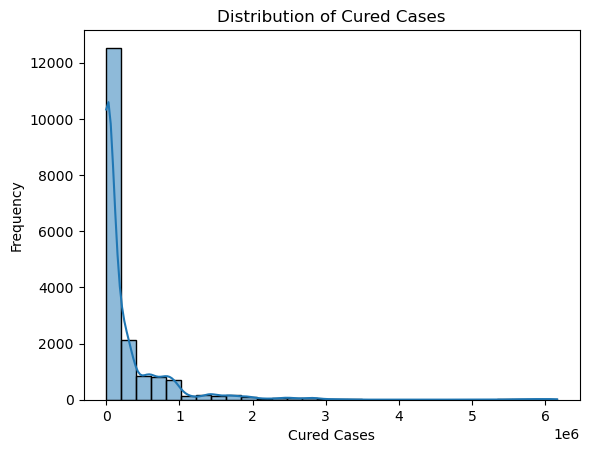

In [36]:
sns.histplot(covid["cured"], bins=30,kde=True)
plt.title("Distribution of Cured Cases")
plt.xlabel("Cured Cases")
plt.ylabel("Frequency")
plt.show()

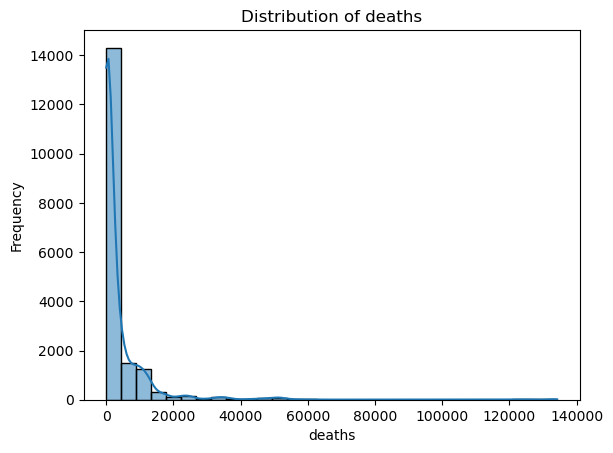

In [38]:
sns.histplot(covid["deaths"], bins=30,kde=True)
plt.title("Distribution of deaths")
plt.xlabel("deaths")
plt.ylabel("Frequency")
plt.show()

# Bi-variate

In [39]:
covid[["deaths","cured","confirmed"]].describe()

,deaths,cured,confirmed
count,18110.000000,1.811000e+04,1.811000e+04
mean,4052.402264,2.786375e+05,3.010314e+05
std,10919.076411,6.148909e+05,6.561489e+05
min,0.000000,0.000000e+00,0.000000e+00
25%,32.000000,3.360250e+03,4.376750e+03
50%,588.000000,3.336400e+04,3.977350e+04
75%,3643.750000,2.788698e+05,3.001498e+05
max,134201.000000,6.159676e+06,6.363442e+06


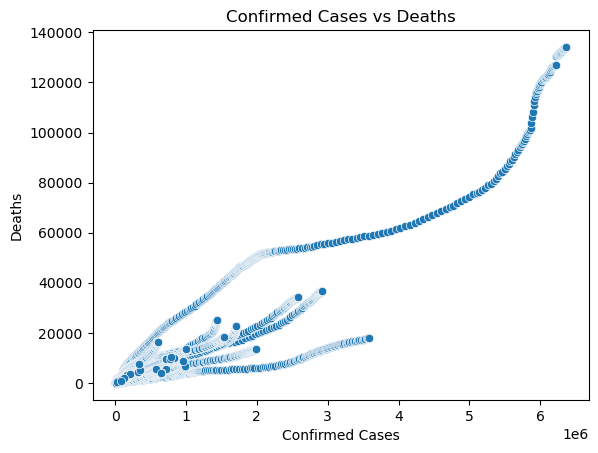

In [40]:
sns.scatterplot(data=covid, x="confirmed", y="deaths")

plt.title("Confirmed Cases vs Deaths")
plt.xlabel("Confirmed Cases")
plt.ylabel("Deaths")
plt.show()

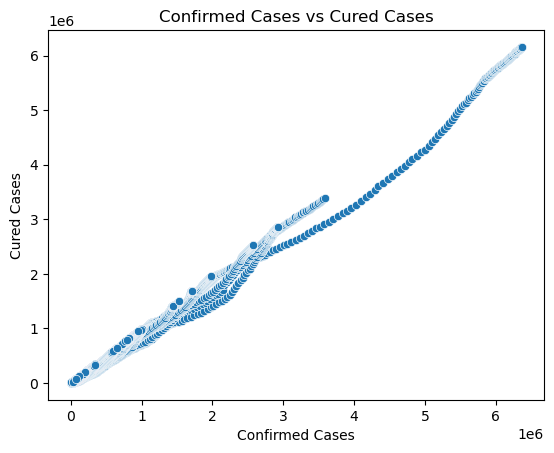

In [41]:
sns.scatterplot(data=covid, x="confirmed", y="cured")

plt.title("Confirmed Cases vs Cured Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Cured Cases")
plt.show()

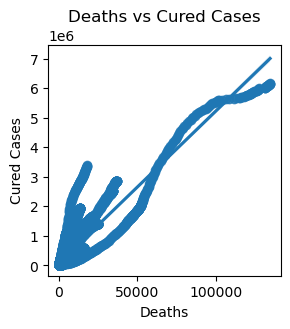

In [96]:
plt.figure(figsize=(3,3))
sns.regplot(data=covid, x="deaths", y="cured")
plt.title("Deaths vs Cured Cases")
plt.xlabel("Deaths")
plt.ylabel("Cured Cases")
plt.show()

In [43]:
covid["confirmed"].corr(covid["cured"])

np.float64(0.9977507277134388)

In [44]:
covid["deaths"].corr(covid["cured"])

np.float64(0.9175293686952284)

In [45]:
covid["deaths"].corr(covid["confirmed"])

np.float64(0.9183455258319997)

# multivariate analysis

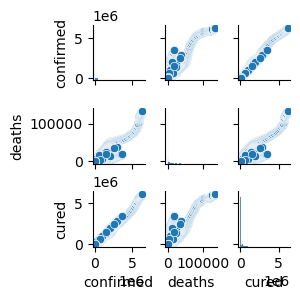

In [90]:
sns.pairplot(
    covid[["confirmed", "deaths", "cured"]],
    height=1,
    aspect=1
)

plt.show()

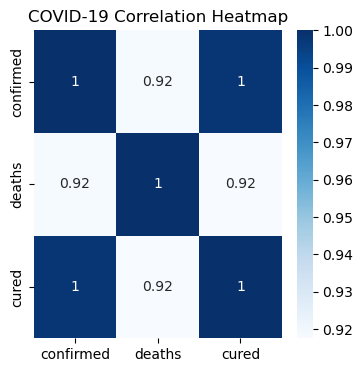

In [87]:
plt.figure(figsize=(4, 4))
covid[["confirmed", "deaths", "cured"]]

sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("COVID-19 Correlation Heatmap")
plt.show()

In [83]:
covid = covid.sort_values("date")
covid

,date,time,state/unionterritory,cured,deaths,confirmed,year,month
0,2020-01-30,6:00 PM,Kerala,0,0,1,2020,1
1,2020-01-31,6:00 PM,Kerala,0,0,1,2020,1
2,2020-02-01,6:00 PM,Kerala,0,0,2,2020,2
3,2020-02-02,6:00 PM,Kerala,0,0,3,2020,2
4,2020-02-03,6:00 PM,Kerala,0,0,3,2020,2
...,...,...,...,...,...,...,...,...
18105,2021-08-11,8:00 AM,Telangana,638410,3831,650353,2021,8
18106,2021-08-11,8:00 AM,Tripura,77811,773,80660,2021,8
18092,2021-08-11,8:00 AM,Lakshadweep,10165,51,10263,2021,8
18091,2021-08-11,8:00 AM,Ladakh,20130,207,20411,2021,8


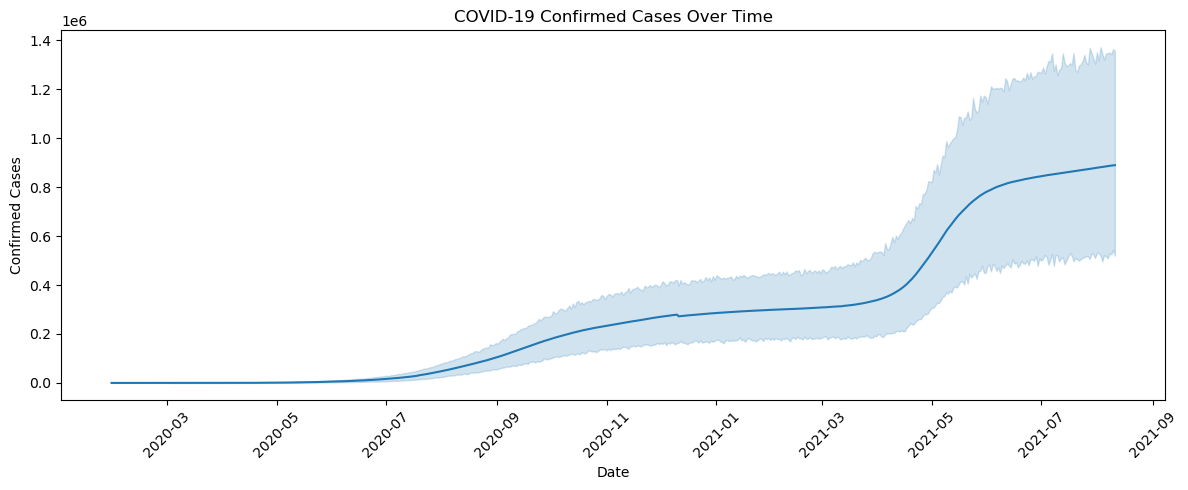

In [82]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=covid, x="date", y="confirmed")

plt.title("COVID-19 Confirmed Cases Over Time")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [103]:
covid.groupby("date")[["confirmed", "deaths", "cured"]].sum().head(5)

,confirmed,deaths,cured
date,,,
2020-01-30,1,0,0
2020-01-31,1,0,0
2020-02-01,2,0,0
2020-02-02,3,0,0
2020-02-03,3,0,0


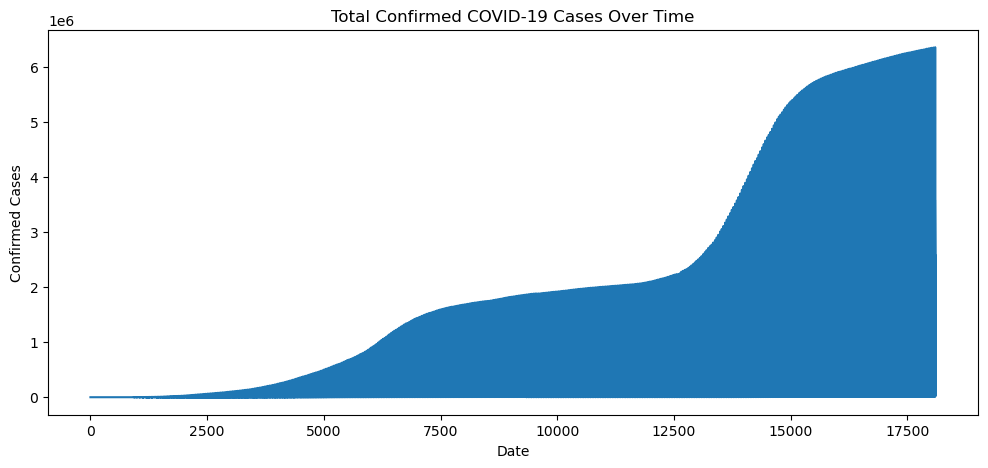

In [101]:
covid["confirmed"].plot(figsize=(12, 5))

plt.title("Total Confirmed COVID-19 Cases Over Time")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")

plt.show()

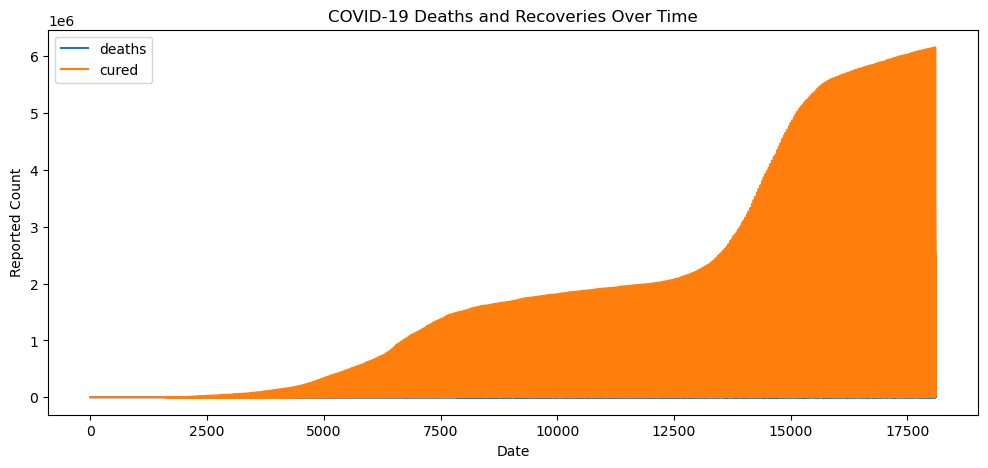

In [105]:
covid[["deaths", "cured"]].plot(figsize=(12, 5))

plt.title("COVID-19 Deaths and Recoveries Over Time")
plt.xlabel("Date")
plt.ylabel("Reported Count")

plt.show()

In [122]:
covid.groupby("state/unionterritory")[["confirmed","cured","deaths"]].max().sort_values("confirmed",ascending=False).head(2)

,confirmed,cured,deaths
state/unionterritory,,,
Maharashtra,6363442,6159676,134201
Maharashtra***,6229596,6000911,130753


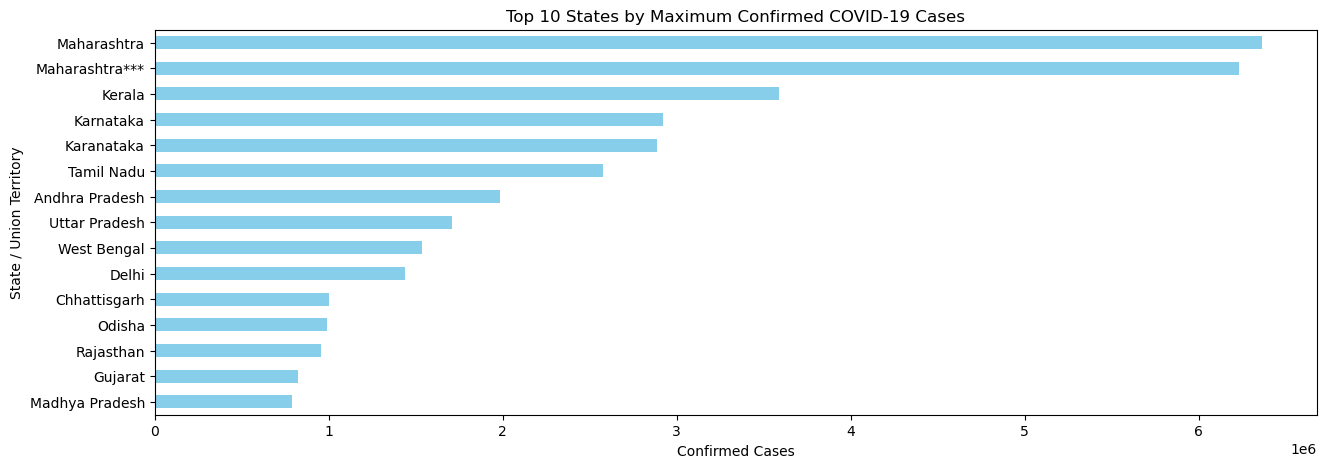

In [114]:
plt.figure(figsize=(15, 5))
state_cases.head(15).plot(kind='barh', color='skyblue')
plt.title("Top 10 States by Maximum Confirmed COVID-19 Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("State / Union Territory")
plt.gca().invert_yaxis()  # Puts the highest value at the top
plt.show()

In [123]:
covid.to_csv("covid_cleaned.csv", index=False)

In [124]:
import os

print(os.getcwd())

C:\Users\pc


In [125]:
import os

print(os.getcwd())
print(os.path.exists("covid_cleaned.csv"))

C:\Users\pc
True
